# Stage 1 — Project Setup and Configuration
RL-Based Adaptive Stress Testing: portfolio, market factors, experiment settings and seeds. Values are read from `config/default.toml`; no market data is downloaded.

## 1. Project setup

In [1]:
import math
import platform
import random
import sys
import tomllib
from datetime import date
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 60)

# Locate the project root (folder holding config/default.toml) from the notebook's working directory.
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "default.toml").is_file()),
    None,
)
assert PROJECT_ROOT is not None, "config/default.toml not found; run the notebook from inside the project"
CONFIG_PATH = PROJECT_ROOT / "config" / "default.toml"

assert sys.version_info >= (3, 11), "tomllib requires Python 3.11+"

env = pd.DataFrame(
    {
        "component": ["Python", "Platform", "NumPy", "pandas", "matplotlib", "Project root", "Config file"],
        "value": [
            platform.python_version(),
            platform.platform(),
            np.__version__,
            pd.__version__,
            matplotlib.__version__,
            str(PROJECT_ROOT),
            str(CONFIG_PATH.relative_to(PROJECT_ROOT)),
        ],
    }
)
env

,component,value
0,Python,3.14.7
1,Platform,macOS-26.6.2-arm64-arm-64bit-Mach-O
2,NumPy,2.5.4
3,pandas,3.0.6
4,matplotlib,3.11.2
5,Project root,RS-RL
6,Config file,config/default.toml


## 2. Configuration loading

In [2]:
# Same parser the project uses (standard-library tomllib); only the TOML data file is read.
with CONFIG_PATH.open("rb") as fh:
    RAW_CONFIG = tomllib.load(fh)

portfolio_cfg = RAW_CONFIG["portfolio"]
data_cfg = RAW_CONFIG["data"]
simulation_cfg = RAW_CONFIG["simulation"]
training_cfg = RAW_CONFIG["training"]

# Reproducibility: the project-wide data seed seeds Python and NumPy for this notebook.
GLOBAL_SEED = int(data_cfg["seed"])
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
RNG = np.random.default_rng(GLOBAL_SEED)

# Historical period and chronological splits, used by the validation and summary cells.
DATA_START = date.fromisoformat(data_cfg["start_date"])
DATA_END = date.fromisoformat(data_cfg["end_date"])
SPLITS = {name: (date.fromisoformat(s), date.fromisoformat(e)) for name, (s, e) in data_cfg["splits"].items()}

print(f"Loaded {CONFIG_PATH.relative_to(PROJECT_ROOT)}")
print("Top-level sections:", ", ".join(RAW_CONFIG))
print(f"Global seed set to {GLOBAL_SEED} (random, numpy)")
print(f"Data period {DATA_START} -> {DATA_END}; splits: {', '.join(SPLITS)}")

Loaded config/default.toml
Top-level sections: portfolio, risk, simulation, environment, training, recommendation, mitigation, storage, data
Global seed set to 42 (random, numpy)
Data period 2015-01-01 -> 2025-12-31; splits: train, validation, test


## 3. Portfolio configuration

In [3]:
assets = data_cfg["assets"]
stock_meta = {a["alias"]: a for a in assets if a["group"] == "stock" and a.get("enabled", True)}

weights = pd.Series(portfolio_cfg["weights"], name="weight", dtype=float)
INITIAL_CAPITAL = float(portfolio_cfg["initial_capital"])
BASE_CURRENCY = portfolio_cfg["base_currency"]

portfolio_df = pd.DataFrame(
    {
        "ticker": weights.index,
        "company": [stock_meta[t]["name"] for t in weights.index],
        "sector": [stock_meta[t]["sector"] for t in weights.index],
        "weight": weights.values,
        "weight_pct": weights.values * 100,
        f"allocation_{BASE_CURRENCY}": weights.values * INITIAL_CAPITAL,
    }
)

settings_df = pd.DataFrame(
    {
        "setting": ["name", "initial_capital", "base_currency", "policy", "rebalancing", "missing_data_policy"],
        "value": [
            portfolio_cfg["name"],
            f"{INITIAL_CAPITAL:,.2f}",
            BASE_CURRENCY,
            portfolio_cfg["policy"],
            portfolio_cfg["rebalancing"],
            portfolio_cfg["missing_data_policy"],
        ],
    }
)
display(settings_df)
display(
    portfolio_df.style.format(
        {"weight": "{:.4f}", "weight_pct": "{:.2f}%", f"allocation_{BASE_CURRENCY}": "{:,.2f}"}
    ).hide(axis="index")
)
print(f"Total weight: {weights.sum():.6f}   Total allocated: {portfolio_df[f'allocation_{BASE_CURRENCY}'].sum():,.2f} {BASE_CURRENCY}")

,setting,value
0,name,us_equity_8_equal_weight
1,initial_capital,"100,000.00"
2,base_currency,USD
3,policy,long_only
4,rebalancing,daily_constant_mix
5,missing_data_policy,complete_case


ticker,company,sector,weight,weight_pct,allocation_USD
AAPL,Apple,Technology,0.1250,12.50%,"12,500.00"
MSFT,Microsoft,Technology,0.1250,12.50%,"12,500.00"
NVDA,NVIDIA,Semiconductors,0.1250,12.50%,"12,500.00"
JPM,JPMorgan Chase,Financials,0.1250,12.50%,"12,500.00"
XOM,Exxon Mobil,Energy,0.1250,12.50%,"12,500.00"
JNJ,Johnson & Johnson,Healthcare,0.1250,12.50%,"12,500.00"
WMT,Walmart,Consumer staples / retail,0.1250,12.50%,"12,500.00"
CAT,Caterpillar,Industrials,0.1250,12.50%,"12,500.00"


Total weight: 1.000000   Total allocated: 100,000.00 USD


## 4. Market factor configuration

In [4]:
FACTOR_COLUMNS = simulation_cfg["factors"]  # e.g. ["SPY_return", "QQQ_return"]
FACTORS = [c.removesuffix("_return") for c in FACTOR_COLUMNS]
asset_by_alias = {a["alias"]: a for a in assets}

factor_df = pd.DataFrame(
    {
        "factor": FACTORS,
        "name": [asset_by_alias[f]["name"] for f in FACTORS],
        "role": [asset_by_alias[f]["role"] for f in FACTORS],
        "model_column": FACTOR_COLUMNS,
        "market_factor": [True] * len(FACTOR_COLUMNS),
    }
)

display(factor_df.style.hide(axis="index"))

# Stock-to-factor rolling-correlation pairs defined for feature engineering.
pairs = data_cfg["features"]["correlation_pairs"]

pairs_df = pd.DataFrame(
    {
        "stock": list(pairs.keys()),
        "paired_factors": [
            ", ".join(f for f in v if f.removesuffix("_return") in FACTORS)
            for v in pairs.values()
        ],
    }
)

display(pairs_df.style.hide(axis="index"))

factor,name,role,model_column,market_factor
SPY,SPDR S&P 500 ETF,S&P 500 / broad US equity market,SPY_return,True
QQQ,Invesco QQQ Trust,Nasdaq-100 / technology-heavy market,QQQ_return,True
XLF,Financial Select Sector SPDR,Financial-sector indicator,XLF_return,True
XLE,Energy Select Sector SPDR,Energy-sector indicator,XLE_return,True


stock,paired_factors
AAPL,"SPY, QQQ"
MSFT,"SPY, QQQ"
NVDA,"SPY, QQQ"
JPM,"SPY, XLF"
XOM,"SPY, XLE"
JNJ,SPY
WMT,SPY
CAT,SPY


## 5. Portfolio allocation chart

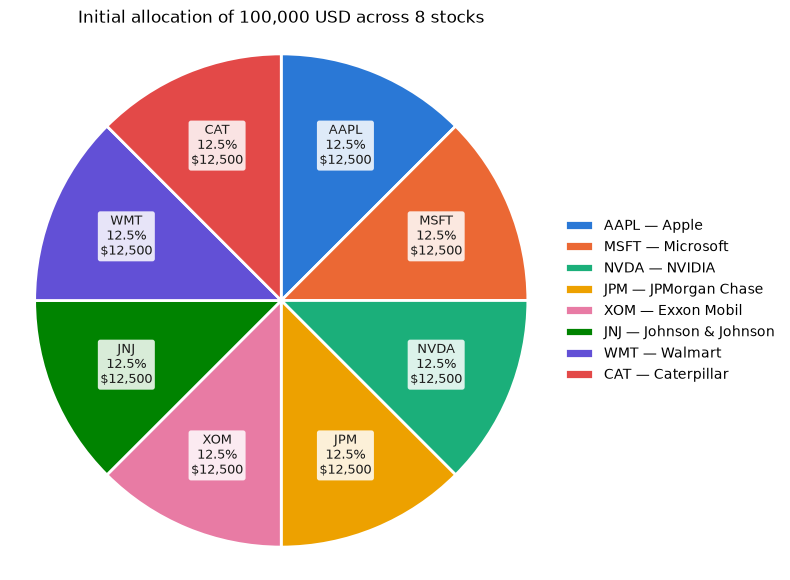

In [5]:
# Fixed categorical order (validated 8-hue palette); colour follows the ticker.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
TICKER_COLORS = dict(zip(portfolio_df["ticker"], PALETTE))

fig, ax = plt.subplots(figsize=(7, 7))
wedges, _ = ax.pie(
    portfolio_df["weight"],
    colors=[TICKER_COLORS[t] for t in portfolio_df["ticker"]],
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
)
for w, (_, row) in zip(wedges, portfolio_df.iterrows()):
    ang = math.radians((w.theta1 + w.theta2) / 2)
    ax.annotate(
        f"{row['ticker']}\n{row['weight_pct']:.1f}%\n${row[f'allocation_{BASE_CURRENCY}']:,.0f}",
        xy=(0.68 * math.cos(ang), 0.68 * math.sin(ang)),
        ha="center", va="center", fontsize=9, color="#1a1a19",
        bbox={"boxstyle": "round,pad=0.2", "fc": "white", "ec": "none", "alpha": 0.85},
    )
ax.legend(wedges, [f"{t} — {stock_meta[t]['name']}" for t in portfolio_df["ticker"]],
          loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
ax.set_title(f"Initial allocation of {INITIAL_CAPITAL:,.0f} {BASE_CURRENCY} across {len(portfolio_df)} stocks")
ax.axis("equal")
plt.show()

## 6. Portfolio weight chart

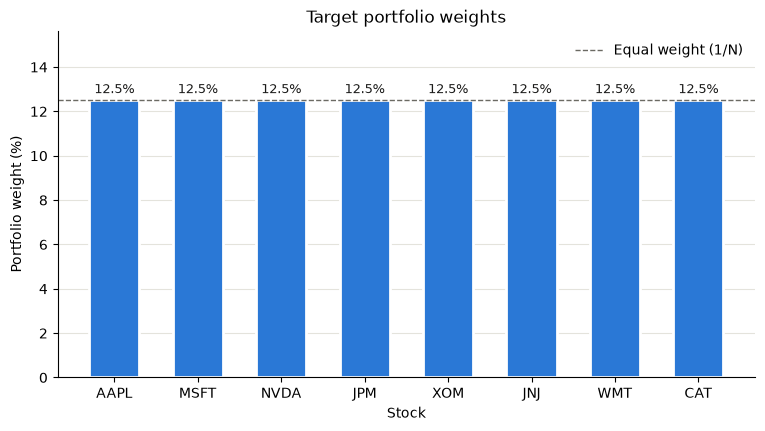

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(portfolio_df["ticker"], portfolio_df["weight_pct"], color="#2a78d6", width=0.6,
              edgecolor="white", linewidth=2)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in portfolio_df["weight_pct"]], padding=3, fontsize=9, color="#1a1a19")
ax.axhline(100 / len(portfolio_df), color="#6b6a63", linewidth=1, linestyle="--", label="Equal weight (1/N)")
ax.set_ylabel("Portfolio weight (%)")
ax.set_xlabel("Stock")
ax.set_title("Target portfolio weights")
ax.set_ylim(0, portfolio_df["weight_pct"].max() * 1.25)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e4e3dc", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper right")
plt.show()

In [7]:
EXPECTED_STOCKS = ["AAPL", "MSFT", "NVDA", "JPM", "XOM", "JNJ", "WMT", "CAT"]
EXPECTED_FACTORS = ["SPY", "QQQ", "XLF", "XLE"]
tol = float(portfolio_cfg["weight_tolerance"])

checks = []

def check(name, condition, detail=""):
    checks.append({"check": name, "result": "PASS" if condition else "FAIL", "detail": detail})

check("Stock count is 8", len(weights) == 8, f"{len(weights)} stocks")
check("Stocks match project universe", sorted(weights.index) == sorted(EXPECTED_STOCKS), ", ".join(weights.index))
check("Every weighted stock defined in data.assets", set(weights.index) <= set(stock_meta), "")
check("Factor count is 4", len(FACTORS) == 4, f"{len(FACTORS)} factors")
check("Factors are SPY, QQQ, XLF, XLE", FACTORS == EXPECTED_FACTORS, ", ".join(FACTORS))
check("Market factor is one of the factors", simulation_cfg["market_factor"] in FACTOR_COLUMNS, simulation_cfg["market_factor"])
check("Weights non-negative", bool((weights >= 0).all()), f"min = {weights.min():.4f}")
check("Weights sum to 1", abs(weights.sum() - 1.0) <= tol, f"sum = {weights.sum():.10f} (tol {tol:g})")
check("Equal-weighted start", np.allclose(weights, 1 / len(weights)), f"each = {1 / len(weights):.4f}")
check("Initial capital positive and finite", INITIAL_CAPITAL > 0 and math.isfinite(INITIAL_CAPITAL), f"{INITIAL_CAPITAL:,.2f} {BASE_CURRENCY}")
check("Allocations sum to capital", math.isclose(portfolio_df[f"allocation_{BASE_CURRENCY}"].sum(), INITIAL_CAPITAL), "")
check("Data start before end", DATA_START < DATA_END, f"{DATA_START} -> {DATA_END}")
check("Historical period 2015-2025", DATA_START.year == 2015 and DATA_END.year == 2025, f"{DATA_START.year}-{DATA_END.year}")
check("Splits in order train/validation/test", list(SPLITS) == ["train", "validation", "test"], ", ".join(SPLITS))

prev_end = None
for name, (s, e) in SPLITS.items():
    check(f"{name}: start <= end", s <= e, f"{s} -> {e}")
    check(f"{name}: inside data range", DATA_START <= s and e <= DATA_END, "")
    if prev_end is not None:
        check(f"{name}: starts after previous split (chronological, no overlap)", s > prev_end, f"previous end {prev_end}")
    prev_end = e

check("Seeds are integers", all(isinstance(x, int) for x in
      [data_cfg["seed"], simulation_cfg["seed"], *training_cfg["seeds"], training_cfg["test_seed"]]), "")
check("Training seeds unique", len(set(training_cfg["seeds"])) == len(training_cfg["seeds"]), str(training_cfg["seeds"]))

checks_df = pd.DataFrame(checks)
display(checks_df.style.hide(axis="index").map(
    lambda v: "color: #008300; font-weight: bold" if v == "PASS" else ("color: #e34948; font-weight: bold" if v == "FAIL" else ""),
    subset=["result"],
))

failed = checks_df[checks_df["result"] == "FAIL"]
assert failed.empty, f"Configuration checks failed: {failed['check'].tolist()}"

check,result,detail
Stock count is 8,PASS,8 stocks
Stocks match project universe,PASS,"AAPL, MSFT, NVDA, JPM, XOM, JNJ, WMT, CAT"
Every weighted stock defined in data.assets,PASS,
Factor count is 4,PASS,4 factors
"Factors are SPY, QQQ, XLF, XLE",PASS,"SPY, QQQ, XLF, XLE"
Market factor is one of the factors,PASS,SPY_return
Weights non-negative,PASS,min = 0.1250
Weights sum to 1,PASS,sum = 1.0000000000 (tol 1e-08)
Equal-weighted start,PASS,each = 0.1250
Initial capital positive and finite,PASS,"100,000.00 USD"


## 9. Completion output

In [8]:
n_pass = int((checks_df["result"] == "PASS").sum())
print("Stage 1 configuration summary")
print("-" * 40)
print(f"Stocks ({len(weights)}):    {', '.join(weights.index)}")
print(f"Factors ({len(FACTORS)}):    {', '.join(FACTORS)}")
print(f"Capital:        {INITIAL_CAPITAL:,.2f} {BASE_CURRENCY} ({portfolio_cfg['policy']}, equal weight {1 / len(weights):.1%})")
print(f"Period:         {DATA_START} -> {DATA_END}")
for name, (s, e) in SPLITS.items():
    print(f"  {name:<11}   {s} -> {e}")
print(f"Global seed:    {GLOBAL_SEED}")
print(f"Checks:         {n_pass}/{len(checks_df)} PASS")
print("STAGE 1 COMPLETE" if n_pass == len(checks_df) else "STAGE 1 INCOMPLETE")

Stage 1 configuration summary
----------------------------------------
Stocks (8):    AAPL, MSFT, NVDA, JPM, XOM, JNJ, WMT, CAT
Factors (4):    SPY, QQQ, XLF, XLE
Capital:        100,000.00 USD (long_only, equal weight 12.5%)
Period:         2015-01-01 -> 2025-12-31
  train         2015-01-01 -> 2021-12-31
  validation    2022-01-01 -> 2023-12-31
  test          2024-01-01 -> 2025-12-31
Global seed:    42
Checks:         24/24 PASS
STAGE 1 COMPLETE
